# Libraries

In [1]:
# PACKAGES
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy as sp
from scipy import special, math, optimize, integrate, interpolate
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import copy
import time
import random
import pandas as pd
import math
import uuid
from scipy.interpolate import interp1d
%matplotlib inline
from datetime import datetime

# Some warnings show up during the resolution of ODEs, but aren't important to the analysis.
import warnings
warnings.filterwarnings('ignore')

# The magnetic fields are in a separate file.
from mag_field import Bz, Btheta, dBz, dBtheta

# Preliminaries for the evaluation of the dispersion function

In [2]:
# PARAMETERS (normalized; don't change)
y0 = [1, 0] # Initial condition for Euler-Lagrange
R = 1
R0, Rf = 1e-3*R, (1-1e-3)*R

# AUXILIARY FUNCTIONS:

def F(r, m, k, q, alpha):
    return k*Bz(r, q, alpha) + m*Btheta(r, q, alpha)/r

def f(r, m, k, l, q, alpha):
    return r**3*(F(r, m, k, q, alpha)**2 + l)/(m**2 + (k**2)*(r**2))

def df(r, m, k, l, q, alpha):
    dF = k*dBz(r, q, alpha) + m*(dBtheta(r, q, alpha)/r - Btheta(r, q, alpha)/r**2)
    a = r**2*(F(r, m, k, q, alpha)**2 + l)*(3*m**2 + k**2*r**2)/((m**2 + k**2*r**2)**2)
    b = 2*F(r, m, k, q, alpha)*dF*r**3/(m**2 + k**2*r**2)
    return a + b

def g(r, m, k, l, q, alpha):
    den = m**2 + k**2*r**2
    a = (1-(m**2-k**2*r**2)/den**2)*r*(F(r, m, k, q, alpha)**2 + l)
    b1 = 4*m*F(r, m, k, q, alpha)*Btheta(r, q, alpha)/den
    b2 = 2*Btheta(r, q, alpha)*dBtheta(r, q, alpha) + 2*Bz(r, q, alpha)*dBz(r, q, alpha)
    b3 = 2*Btheta(r, q, alpha)**2/r*(2*F(r, m, k, q, alpha)**2/(F(r, m, k, q, alpha)**2 + l) - 1)
    b = k**2*r**2/den*(b1 + b2 + b3)
    return a - b

def F_euler(r, y, m, k, l, q, alpha):
    aux = (g(r, m, k, l, q, alpha)*y[0] - df(r, m, k, l, q, alpha)*y[1])/f(r, m, k, l, q, alpha)
    return np.array([y[1], aux])

def bound_cond_D(m, k, l, xiR, dxiR, q, alpha):
    mod2 = Bz(R, q, alpha)**2 + Btheta(R, q, alpha)**2
    aux = ((m**2 + k**2*R**2)*special.kn(m, abs(k)*R))/(abs(k)*R*special.kn(m-1, abs(k)*R) + m*special.kn(m, abs(k)*R))
    return xiR*(k**2*mod2 + l*(1+aux)) + dxiR*R*(F(R, m, k, q, alpha)**2 + l)

# Evaluation of the dispersion function

In [3]:
# Evaluation of the dispersion function.
# If printsol = True, we plot the solution xi_r.
def disp_F(l, m, k, q, alpha, printsol = False):
    aux_euler2 = lambda y, r : F_euler(r, y, m, k, l, q, alpha)
    rr = np.linspace(R0, Rf, n_ite+1)
    sol2 = integrate.odeint(aux_euler2, y0, rr)
    xiR2, dxiR2 = sol2[-1][0], sol2[-1][1]
    if printsol:
        axes = [r'$r$', r'$\xi_r$']
        title = 'Most unstable perturbation'
        perturbation = [elem[0] for elem in sol2]
        lineplot(rr, perturbation/abs(xiR2), axes, title, markzero = True)
        print('xi(0)= ', sol2[0][0], ', xi\'(0)= ', sol2[0][1])
        print('xi(R)= ', xiR2, ', xi\'(R)= ', R*dxiR2)
    return bound_cond_D(m, k, l, xiR2, dxiR2, q, alpha)

def lininterp(x0, y0, x1, y1, x2):
    m = (y1-y0)/(x1-x0)
    y2 = y1 + m*(x2-x1)
    return y2

# Finds the biggest root of a function in a given interval.
def biggest_root(func_Dlk, l_range):
    D_lk = []
    for l in l_range:
        D_lk.append(func_Dlk(l))
    all_same_sign = all(x > 0 for x in D_lk) or all(x < 0 for x in D_lk)
    if not all_same_sign:
        i = len(D_lk) - 1
        # We are only interested in finding the biggest zero.
        while np.sign(D_lk[i])*np.sign(D_lk[i-1]) > 0:
            i = i - 1
        # Linear interpolation to find the zero. We could do a dicotomic search, but it would be slower.
        return lininterp(D_lk[i-1], l_range[i-1], D_lk[i], l_range[i], 0)
    else:
        return 0

# Finds the dispersion relation between k and lambda, given the magnetic field configuration.
def dispersion_relation(alpha, q, m, k_vals, n_k, l_vals, n_l):
    ks = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l)) # logarithmically spaced.
    ls = []
    for k in ks:
        D = []
        func_D = lambda l : disp_F(l, m, k, q, alpha) # Definition of a single variable function D(l).
        l = biggest_root(func_D, l_range)
        ls.append(l)
    return ks, ls

# Finding the max growth rate for each magnetic field configuration

In [4]:
# Slightly different from original notebook, as this one also returns the curve (k_range, lambdas)
def lambdamax(alpha, q, m, k_vals, n_k, l_vals, n_l):
    k_range = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l))
    lmax = 0
    kmax = 0
    lambdas = []
    for k in k_range:
        func_Dlk = lambda l, k=k: disp_F(l, m, k, q, alpha)
        l = biggest_root(func_Dlk, l_range)
        lambdas.append(l)
        if l > lmax:
            lmax = l
            kmax = k
    return lmax, kmax, k_range, lambdas

# ICME data

In [5]:
# Physical constants
mp    = 1.673e-27 # proton mass in Kg
ratio = 1.16 # proton density to mass density ratio (num of helium ions is 4% but have 4x the mass of a proton)
mu0   = 4 * math.pi * 1e-7 # Permeability
SEC   = 86400 # Num of seconds in a day
AU    = 1.496e11 # AU in metres

# Gold-Hoyle profile
OBS_ALPHA = 1.0

In [6]:
# Density lookup table (median density, from in-situ data)
density_table = pd.DataFrame([
    ("2018-10-30 20:25", "PSP",  178.313),
    ("2018-11-11 23:51", "PSP",  168.320),
    ("2019-03-15 12:11", "PSP",   27.649),
    ("2019-03-24 03:45", "PSP",   50.465),
    ("2020-02-11 05:08", "PSP",   74.548),
    ("2020-06-23 07:07", "PSP",   29.694),
    ("2020-09-12 13:33", "PSP",   24.827),
    ("2021-02-11 16:17", "PSP",   19.910),
    ("2021-05-06 18:26", "SolO",   7.450),
    ("2021-05-27 20:14", "SolO",  16.756),
    ("2021-08-25 01:06", "SolO",  24.286),
    ("2021-10-04 07:01", "SolO",  14.776),
    ("2021-10-15 09:54", "SolO",  24.002),
    ("2021-11-04 01:25", "SolO",   6.783),
    ("2022-01-25 14:02", "SolO",   4.080),
], columns=["start_utc", "spacecraft", "np_p50"])

density_table["start_utc"] = pd.to_datetime(density_table["start_utc"])
 
# Return (np_p50, n_days_diff) for the closest density obs of same spacecraft.
def match_density(t_start_str, sc):
    fmt = "%Y-%m-%d %H:%M"
    t = pd.Timestamp(datetime.strptime(t_start_str, fmt))
    subset = density_table[density_table["spacecraft"] == sc].copy()
    subset["diff"] = (subset["start_utc"] - t).abs()
    best = subset.loc[subset["diff"].idxmin()]
    n_days = best["diff"].total_seconds() / 86400
    return float(best["np_p50"]), round(n_days, 2)

In [7]:
# Obtain T in days from growth rate lambda
def T_days(lam, obs_B0, obs_R, obs_np):
    sigma   = np.sqrt(lam)
    T       = 1.0 / sigma
    obs_rho = ratio * mp * obs_np * 1e6
    factor  = (obs_R / obs_B0) * np.sqrt(mu0 * obs_rho)
    return T * factor / SEC

In [8]:
# ICME table (fitted events only). Source: Good et. al. 2023.
# Columns: event, t_start, t_end, spacegraft, r_au, B0_nT, q
raw_data = [
    ( 1, "2018-10-30 20:25", "2018-10-31 08:19", "PSP",  0.26,  56.0, -5.2),
    ( 2, "2018-11-21 23:51", "2018-11-22 05:59", "PSP",  0.25, 100.6,  7.3),
    ( 3, "2019-03-15 12:11", "2019-03-15 17:49", "PSP",  0.55,  36.0,  3.6),
    ( 4, "2019-03-24 03:45", "2019-03-24 17:38", "PSP",  0.39,  36.7,  3.0),
    ( 5, "2020-02-11 05:08", "2020-02-11 11:35", "PSP",  0.42,  43.6,  4.6),
    ( 7, "2020-06-23 07:07", "2020-06-23 16:52", "PSP",  0.48,  20.1, -2.7),
    ( 9, "2020-09-12 13:33", "2020-09-12 19:35", "PSP",  0.47,  23.7,  9.3),
    (11, "2021-02-11 16:17", "2021-02-12 00:57", "PSP",  0.63,  15.4,  2.6),
    (13, "2021-05-06 18:26", "2021-05-07 15:07", "SolO", 0.91,  13.6, -3.1),
    (15, "2021-05-27 20:14", "2021-05-28 10:27", "SolO", 0.95,  11.1,  4.0),
    (23, "2021-08-25 01:06", "2021-08-25 10:43", "SolO", 0.63,  16.2, -2.3),
    (24, "2021-10-04 07:01", "2021-10-04 12:59", "SolO", 0.65,  11.6, -6.6),
    (26, "2021-10-15 09:54", "2021-10-15 23:11", "SolO", 0.72,  14.7, -2.2),
    (27, "2021-11-04 01:25", "2021-11-04 19:47", "SolO", 0.83,  20.6, -1.0),
    (28, "2022-01-25 14:02", "2022-01-27 07:15", "SolO", 0.89,  12.5, -0.7),
]
n_events = len(raw_data)
 
# Return duration as 'Xd Yh Zm' from start to end of the event.
def fmt_duration(t_start_str, t_end_str):
    fmt = "%Y-%m-%d %H:%M"
    delta = datetime.strptime(t_end_str, fmt) - datetime.strptime(t_start_str, fmt)
    total_minutes = int(delta.total_seconds() // 60)
    d =  total_minutes // (60 * 24)
    h = (total_minutes %  (60 * 24)) // 60
    m =  total_minutes % 60
    parts = []
    if d: parts.append(f"{d}d")
    if h: parts.append(f"{h}h")
    if m: parts.append(f"{m}m")
    return " ".join(parts) if parts else "0m"

# Growth rate analysis for the events above

When running the cell below, after the analysis of each event, the lambda plot is shown.
Worth checking lambdamax is not clipping at k-range edges.
RED dot = kmax found. If it sits at the left or right edge, the k_vals range is too narrow.
If the curve drops to 0 in the middle, means the range for lambda (l_vals) needs widening on the upper bound.

In [9]:
# Types of instability to be analyzed:
ms = [1, 2]

# Numerical PDE solution params:
n_ite  = 30
n_k    = 20
n_l    = 40

In [10]:
# Run growth rate analysis for a subset of events

def run_analysis(raw_data_subset):
    records_out = []

    for (ev, t_start, t_end, sc, r_au, B0_nT, q) in raw_data_subset:
        i_global = next(j+1 for j, rd in enumerate(raw_data) if rd[0] == ev)
        pct = 100 * i_global / n_events
        print(f"\n[{i_global}/{n_events}  {pct:.0f}%]  Event {ev}  |  {sc}  |  "
              f"r={r_au} au  B0={B0_nT} nT  q={q}")

        obs_B0 = B0_nT * 1e-9
        obs_np, n_days_rho = match_density(t_start, sc)
        print(f"  density match: np={obs_np:.2f} cm^-3  (NdaysRho={n_days_rho:.2f})")

        q_abs     = np.abs(q)
        R_rope_au = 1.0 / q_abs
        R_rope_m  = R_rope_au * AU
        print(f"  R_rope = {R_rope_au:.4f} au  (from 1/|q|={q_abs})")
        print(f"  [params: n_ite={n_ite}, l_vals={l_vals}, n_k={n_k}, n_l={n_l}]")

        row = {
            "Event":       ev,
            "Start (UT)":  t_start,
            "Duration":    fmt_duration(t_start, t_end),
            "Mission":     sc,
            "B0 (nT)":     B0_nT,
            "r (au)":      r_au,
            "R_rope (au)": round(R_rope_au, 4),
            "q (au^-1)":   q,
            "np":          round(obs_np, 2),
            "NdaysRho":    n_days_rho,
        }

        fig, axes = plt.subplots(1, len(ms), figsize=(5 * len(ms), 3.5))
        if len(ms) == 1:
            axes = [axes]
        fig.suptitle(f"Event {ev}  |  {sc}  |  q={q}  B0={B0_nT} nT  r={r_au} au",
                     fontsize=10)

        for ax, m in zip(axes, ms):
            k_vals_m = get_k_vals(m, q_abs)
            lam, kmax, k_range, lambdas = lambdamax(OBS_ALPHA, q_abs, m, k_vals_m, n_k, l_vals, n_l)

            span    = k_range[-1] - k_range[0]
            clipped = (lam > 1e-10) and (
                abs(kmax - k_range[0])  < 0.05 * abs(span) or
                abs(kmax - k_range[-1]) < 0.05 * abs(span)
            )

            ax.plot(k_range, lambdas, color="steelblue", lw=1.5)
            ax.axhline(0, color="gray", lw=0.8, ls="--")
            ax.scatter([kmax], [lam], color="red", zorder=5, label=f"kmax={kmax:.3f}")
            ax.set_xlabel("k")
            ax.set_ylabel("lambda")
            ax.legend(fontsize=8)

            if clipped:
                ax.set_facecolor("#fff0f0")
                ax.set_title(f"m={m}  *** EDGE CLIP ***", color="red", fontsize=9)
            else:
                ax.set_title(f"m={m}  lmax={lam:.4f}", fontsize=9)

            if lam > 0:
                T_d   = T_days(lam, obs_B0, R_rope_m, obs_np)
                sigma = 1.0 / T_d
                print(f"  m={m}  ->  sigma={sigma:.4f} d^-1  T={T_d:.2f} days  (k_max={kmax:.4f})")
            else:
                sigma = np.nan
                T_d   = np.nan
                print(f"  m={m}  ->  no unstable mode found")

            row[f"sigma_m{m}"] = round(sigma, 4) if not np.isnan(sigma) else np.nan
            row[f"T_m{m}_d"]   = round(T_d,   2) if not np.isnan(T_d)   else np.nan

        plt.tight_layout()
        plt.show()
        records_out.append(row)

    return records_out


[1/15  7%]  Event 1  |  PSP  |  r=0.26 au  B0=56.0 nT  q=-5.2
  density match: np=178.31 cm^-3  (NdaysRho=0.00)
  R_rope = 0.1923 au  (from 1/|q|=5.2)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0821 d^-1  T=12.18 days  (k_max=-2.9968)
  m=2  ->  sigma=0.0256 d^-1  T=39.03 days  (k_max=-9.1958)


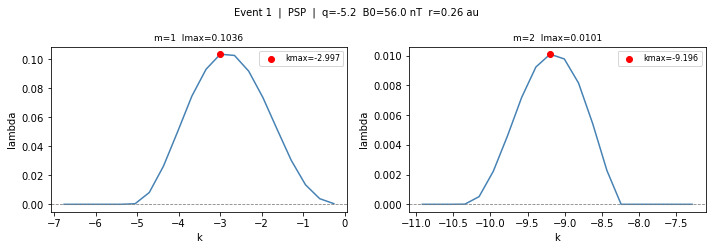


[2/15  13%]  Event 2  |  PSP  |  r=0.25 au  B0=100.6 nT  q=7.3
  density match: np=168.32 cm^-3  (NdaysRho=10.00)
  R_rope = 0.1370 au  (from 1/|q|=7.3)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.2996 d^-1  T=3.34 days  (k_max=-4.2071)
  m=2  ->  sigma=0.0955 d^-1  T=10.47 days  (k_max=-12.9095)


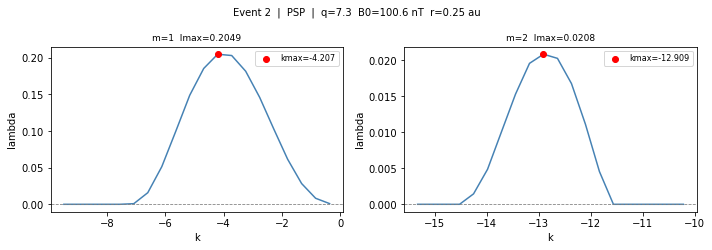


[3/15  20%]  Event 3  |  PSP  |  r=0.55 au  B0=36.0 nT  q=3.6
  density match: np=27.65 cm^-3  (NdaysRho=0.00)
  R_rope = 0.2778 au  (from 1/|q|=3.6)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0640 d^-1  T=15.62 days  (k_max=-2.0747)
  m=2  ->  sigma=0.0202 d^-1  T=49.42 days  (k_max=-6.3663)


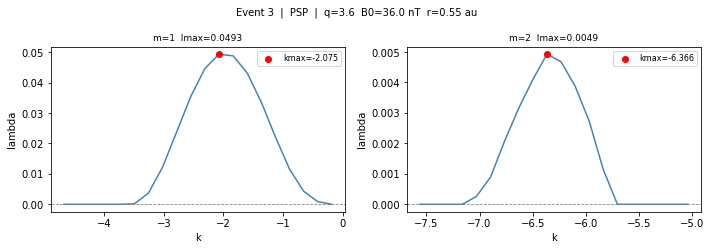


[4/15  27%]  Event 4  |  PSP  |  r=0.39 au  B0=36.7 nT  q=3.0
  density match: np=50.47 cm^-3  (NdaysRho=0.00)
  R_rope = 0.3333 au  (from 1/|q|=3.0)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0334 d^-1  T=29.95 days  (k_max=-1.7289)
  m=2  ->  sigma=0.0103 d^-1  T=97.09 days  (k_max=-5.3053)


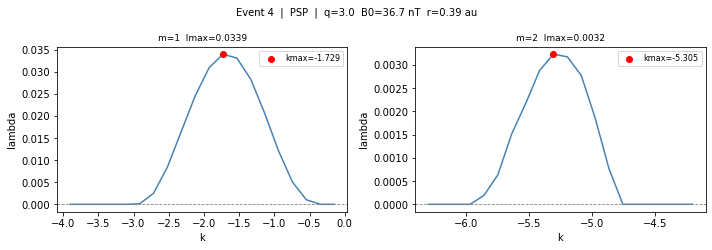


[5/15  33%]  Event 5  |  PSP  |  r=0.42 au  B0=43.6 nT  q=4.6
  density match: np=74.55 cm^-3  (NdaysRho=0.00)
  R_rope = 0.2174 au  (from 1/|q|=4.6)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0773 d^-1  T=12.94 days  (k_max=-2.6511)
  m=2  ->  sigma=0.0239 d^-1  T=41.92 days  (k_max=-8.1347)


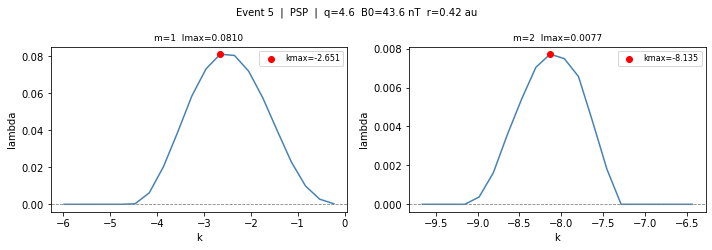


[6/15  40%]  Event 7  |  PSP  |  r=0.48 au  B0=20.1 nT  q=-2.7
  density match: np=29.69 cm^-3  (NdaysRho=0.00)
  R_rope = 0.3704 au  (from 1/|q|=2.7)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0192 d^-1  T=52.15 days  (k_max=-1.5561)
  m=2  ->  sigma=0.0061 d^-1  T=163.75 days  (k_max=-4.7747)


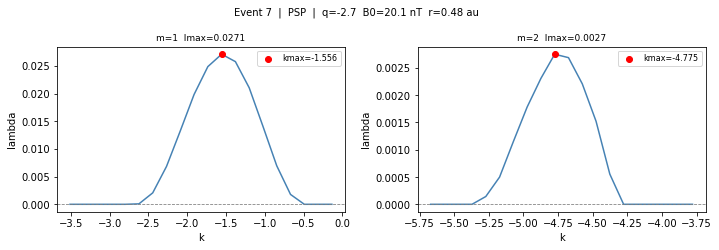


[7/15  47%]  Event 9  |  PSP  |  r=0.47 au  B0=23.7 nT  q=9.3
  density match: np=24.83 cm^-3  (NdaysRho=0.00)
  R_rope = 0.1075 au  (from 1/|q|=9.3)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.2982 d^-1  T=3.35 days  (k_max=-5.3597)
  m=2  ->  sigma=0.0980 d^-1  T=10.20 days  (k_max=-16.4463)


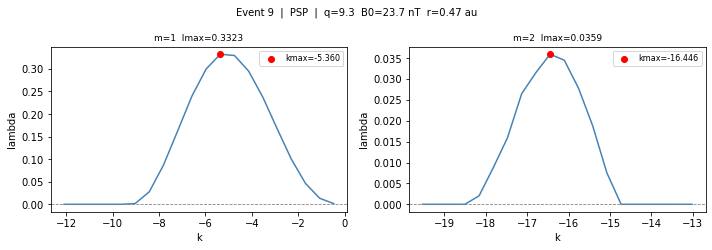


[8/15  53%]  Event 11  |  PSP  |  r=0.63 au  B0=15.4 nT  q=2.6
  density match: np=19.91 cm^-3  (NdaysRho=0.00)
  R_rope = 0.3846 au  (from 1/|q|=2.6)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0166 d^-1  T=60.40 days  (k_max=-1.4984)
  m=2  ->  sigma=0.0052 d^-1  T=192.15 days  (k_max=-4.5979)


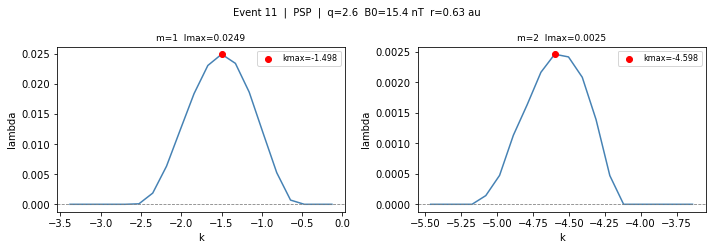


[9/15  60%]  Event 13  |  SolO  |  r=0.91 au  B0=13.6 nT  q=-3.1
  density match: np=7.45 cm^-3  (NdaysRho=0.00)
  R_rope = 0.3226 au  (from 1/|q|=3.1)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0344 d^-1  T=29.03 days  (k_max=-1.7866)
  m=2  ->  sigma=0.0109 d^-1  T=91.66 days  (k_max=-5.4821)


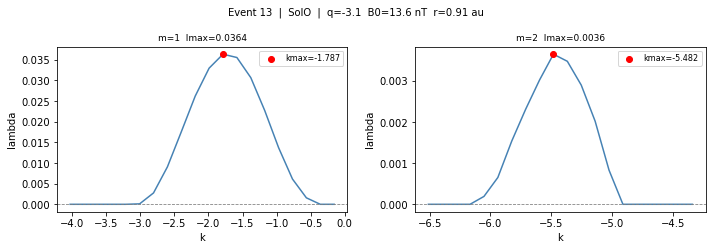


[10/15  67%]  Event 15  |  SolO  |  r=0.95 au  B0=11.1 nT  q=4.0
  density match: np=16.76 cm^-3  (NdaysRho=0.00)
  R_rope = 0.2500 au  (from 1/|q|=4.0)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0313 d^-1  T=31.90 days  (k_max=-2.3053)
  m=2  ->  sigma=0.0096 d^-1  T=104.07 days  (k_max=-7.0737)


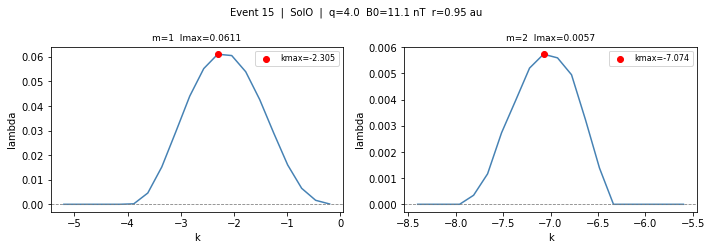


[11/15  73%]  Event 23  |  SolO  |  r=0.63 au  B0=16.2 nT  q=-2.3
  density match: np=24.29 cm^-3  (NdaysRho=0.00)
  R_rope = 0.4348 au  (from 1/|q|=2.3)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0120 d^-1  T=83.36 days  (k_max=-1.3255)
  m=2  ->  sigma=0.0040 d^-1  T=252.89 days  (k_max=-4.0674)


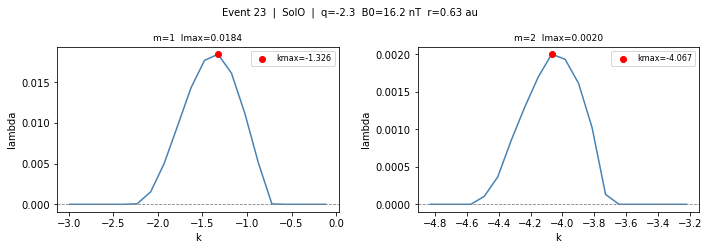


[12/15  80%]  Event 24  |  SolO  |  r=0.65 au  B0=11.6 nT  q=-6.6
  density match: np=14.78 cm^-3  (NdaysRho=0.00)
  R_rope = 0.1515 au  (from 1/|q|=6.6)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0951 d^-1  T=10.52 days  (k_max=-3.8037)
  m=2  ->  sigma=0.0303 d^-1  T=33.05 days  (k_max=-11.6716)


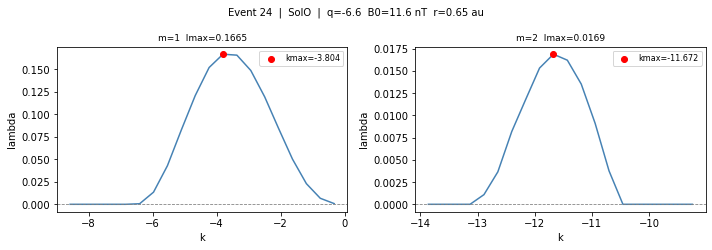


[13/15  87%]  Event 26  |  SolO  |  r=0.72 au  B0=14.7 nT  q=-2.2
  density match: np=24.00 cm^-3  (NdaysRho=0.00)
  R_rope = 0.4545 au  (from 1/|q|=2.2)
  [params: n_ite=30, l_vals=[-5, 0], n_k=20, n_l=40]
  m=1  ->  sigma=0.0098 d^-1  T=101.59 days  (k_max=-1.2679)
  m=2  ->  sigma=0.0032 d^-1  T=308.00 days  (k_max=-3.8905)


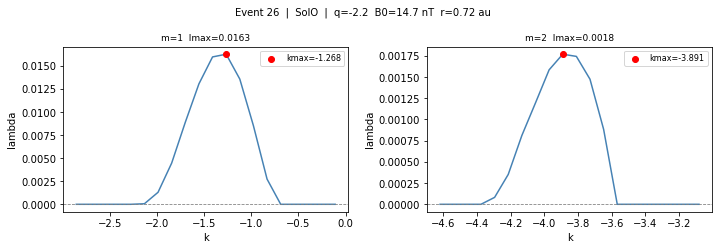


[14/15  93%]  Event 27  |  SolO  |  r=0.83 au  B0=20.6 nT  q=-1.0
  density match: np=6.78 cm^-3  (NdaysRho=0.00)
  R_rope = 1.0000 au  (from 1/|q|=1.0)
  [params: n_ite=30, l_vals=[-7, -3], n_k=20, n_l=40]
  m=1  ->  sigma=0.0022 d^-1  T=445.43 days  (k_max=-0.8421)
  m=2  ->  sigma=0.0012 d^-1  T=802.66 days  (k_max=-1.8474)


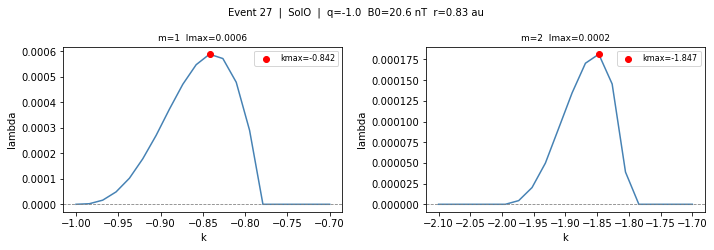


[15/15  100%]  Event 28  |  SolO  |  r=0.89 au  B0=12.5 nT  q=-0.7
  density match: np=4.08 cm^-3  (NdaysRho=0.00)
  R_rope = 1.4286 au  (from 1/|q|=0.7)
  [params: n_ite=30, l_vals=[-7, -3], n_k=20, n_l=40]
  m=1  ->  sigma=0.0004 d^-1  T=2537.66 days  (k_max=-0.6337)
  m=2  ->  sigma=0.0003 d^-1  T=3760.74 days  (k_max=-1.3374)


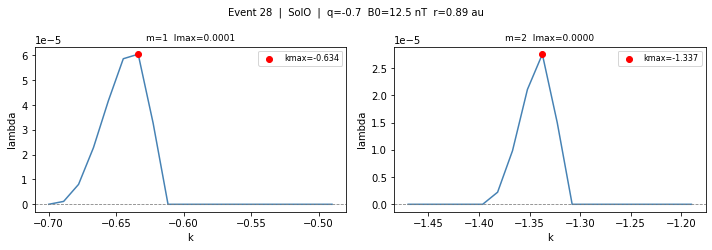


Results saved to icme_instability_results.csv


In [11]:
# Events 1-13
l_vals = [-5, 0]
def get_k_vals(m, q):
    if m == 1:
        return [-1.3 * q, -0.05 * q]
    elif m == 2:
        return [-2.1 * q, -1.4 * q]
    else:
        raise ValueError(f"m={m} not supported. Validate k_vals ranges before extending to higher modes.")
records_1_13 = run_analysis(raw_data[:13])

# Events 14-15 (low-q, needs wider l range and different k ranges)
l_vals = [-7, -3]
def get_k_vals(m, q):
    if m == 1:
        return [-1.0 * q, -0.7 * q]
    elif m == 2:
        return [-2.1 * q, -1.7 * q]
    else:
        raise ValueError(f"m={m} not supported. Validate k_vals ranges before extending to higher modes.")
records_14_15 = run_analysis(raw_data[13:])

# Concatenate and save
df = pd.DataFrame(records_1_13 + records_14_15)
df.to_csv("icme_instability_results.csv", index=False, header=False)
print("\nResults saved to icme_instability_results.csv")

# Write LaTeX table

In [15]:
def fmt_cell(val, decimals=None):
    if pd.isna(val):
        return "$\\cdots$"
    if decimals is not None:
        return f"{float(val):.{decimals}f}"
    return str(val)

tex_rows = []
for _, r in df.iterrows():
    cols = [
        str(int(r["Event"])),
        r["Start (UT)"],
        r["Duration"],
        r["Mission"],
        f"{r['r (au)']:.2f}",
        f"{r['np']:.1f}",
        f"{r['NdaysRho']:.2f}",
        f"{r['B0 (nT)']:.1f}",
        f"{r['q (au^-1)']:.1f}",
        fmt_cell(r["sigma_m1"], 3),
        fmt_cell(r["T_m1_d"],   1),
        fmt_cell(r["sigma_m2"], 3),
        fmt_cell(r["T_m2_d"],   1),
    ]
    tex_rows.append("    " + " & ".join(cols) + " \\\\")

rows_str = "\n".join(tex_rows)

lines = [
    r"% Add \usepackage{booktabs} to your preamble if not already there.",
    r"\begin{table*}[ht]",
    r"  \caption{%",
    r"    Observed parameters and kink instability timescales for 15 ICMEs detected",
    r"    by PSP and Solar Orbiter (SolO).",
    r"    $r$ (au) is the heliocentric distance, $n_p$ (cm$^{-3}$) the median proton",
    r"    density matched from in-situ data, and $\Delta t_\rho$ (d) the time offset",
    r"    of the matched density observation.",
    r"    $B_{0}$ (nT) is the axial field strength and $q$ (au$^{-1}$) the signed",
    r"    twist parameter; the flux rope radius follows as $R=1/|q|$.",
    r"    $\sigma$ (d$^{-1}$) $= 1/T$ is the physical growth rate and $T$ (d) the",
    r"    instability timescale for azimuthal modes $m{=}1$ and $m{=}2$.",
    r"    Gold--Hoyle profile ($\alpha=1$) assumed throughout.",
    r"    Entries ``$\cdots$'' indicate no unstable mode was found.%",
    r"  }",
    r"  \label{tab:icme}",
    r"  \setlength{\tabcolsep}{3pt}",
    r"  \centering",
    r"  \begin{tabular}{c l c c r r r r r r r r r}",
    r"    \toprule",
    r"    \multicolumn{7}{c}{MFR observation} &",
    r"    \multicolumn{2}{c}{G-H Fitting} &",
    r"    \multicolumn{2}{c}{$m=1$} &",
    r"    \multicolumn{2}{c}{$m=2$} \\",
    r"    \cmidrule(lr){1-7}\cmidrule(lr){8-9}\cmidrule(lr){10-11}\cmidrule(lr){12-13}",
    r"    {No.} & {Start (UT)} & {Dur.} & {S/C} & {$r$} & {$n_p$} & {$\Delta t_\rho$} &",
    r"    {$B_{0}$} & {$q$} &",
    r"    {$\sigma$} & {$T$} &",
    r"    {$\sigma$} & {$T$} \\",
    r"    \midrule",
    rows_str,
    r"    \bottomrule",
    r"  \end{tabular}",
    r"\end{table*}",
]
tex = "\n".join(lines)

with open("icme_tables.tex", "w") as f:
    f.write(tex)
print("LaTeX table saved to icme_tables.tex")

LaTeX table saved to icme_tables.tex
